<a href="https://colab.research.google.com/github/luisalberto49703-commits/Codes-for-Luis_Santos_paper_2/blob/main/Newton_Raphson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter the length of the rod [m] L = 0.01
Enter the number of elements N = 10
Enter the linear heat generation [W/m] q = 1000
Enter the final simulation time [s] t_final = 2
Enter the time step [s] dt = .1
Temperature at left boundary [°C] T_left = 100
Temperature at right boundary [°C] T_right = 100
Initial temperature [°C] T_init = 25


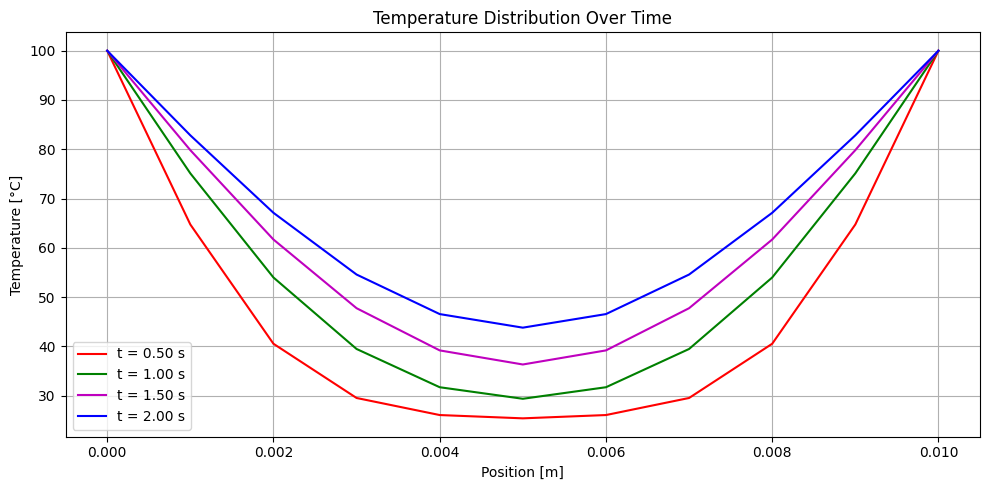

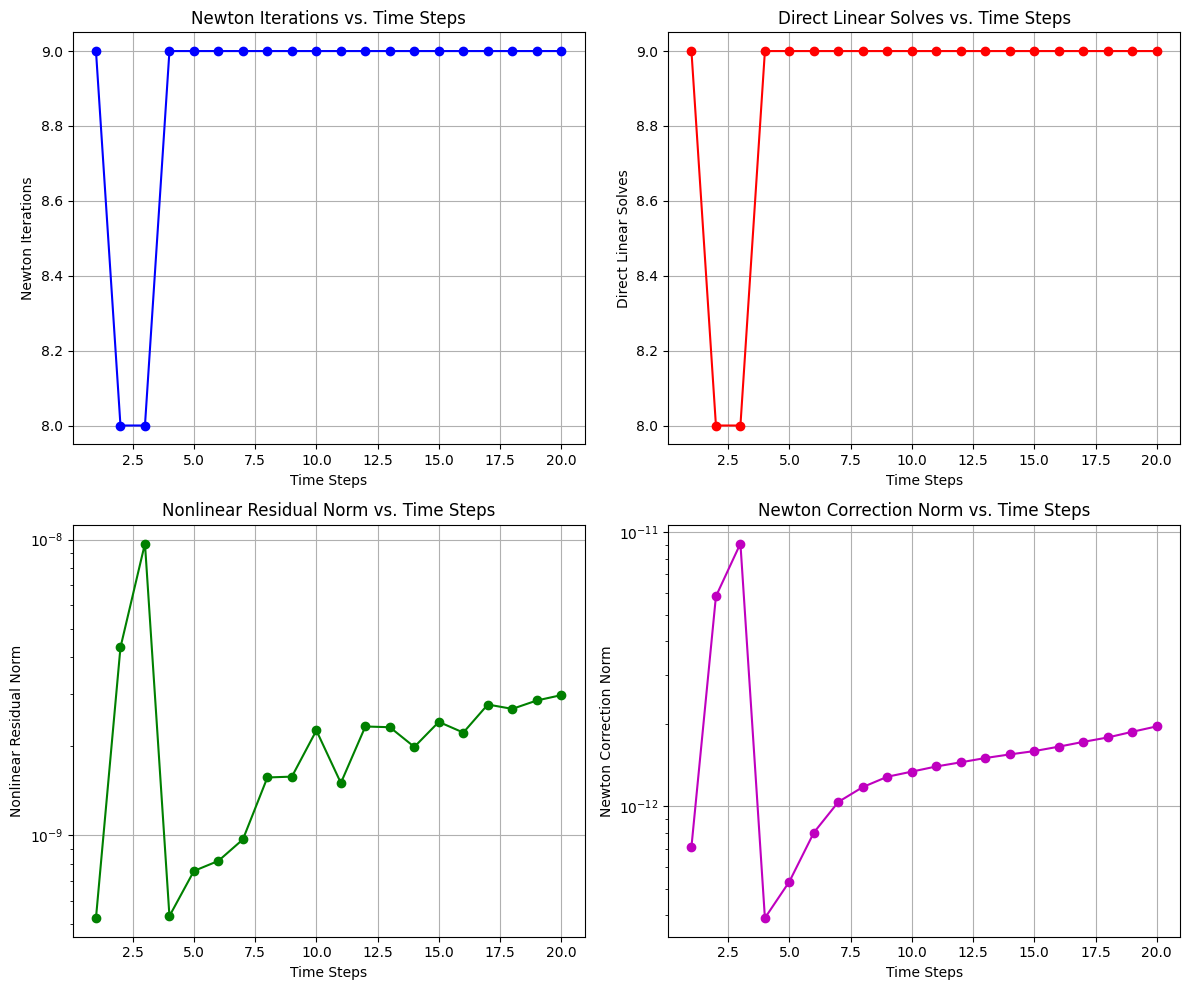


--- Performance Summary ---
Total Newton Iterations: 178
Total Execution Time: 1.985 seconds
Average Newton Iterations per Time Step: 8.90
Final Residual Norm (Nonlinear): 2.98e-09
Final Linear-System Solution Norm: 1.95e-12
Final Temperature Change Norm: 3.46e+00
Memory Usage: 0.30 MB
Approximate Linear-System Solves: 178
Stability Check (max T): 100.00 °C
Robustness: OK

--- Final Temperature Change Norm Study ---
t_final =    2.0 s  -->  Final Temperature Change Norm = 3.46e+00
t_final =   20.0 s  -->  Final Temperature Change Norm = 2.44e-02
t_final =   40.0 s  -->  Final Temperature Change Norm = 9.52e-05
t_final =   50.0 s  -->  Final Temperature Change Norm = 5.94e-06
t_final =   75.0 s  -->  Final Temperature Change Norm = 5.78e-09
t_final =  100.0 s  -->  Final Temperature Change Norm = 5.60e-12


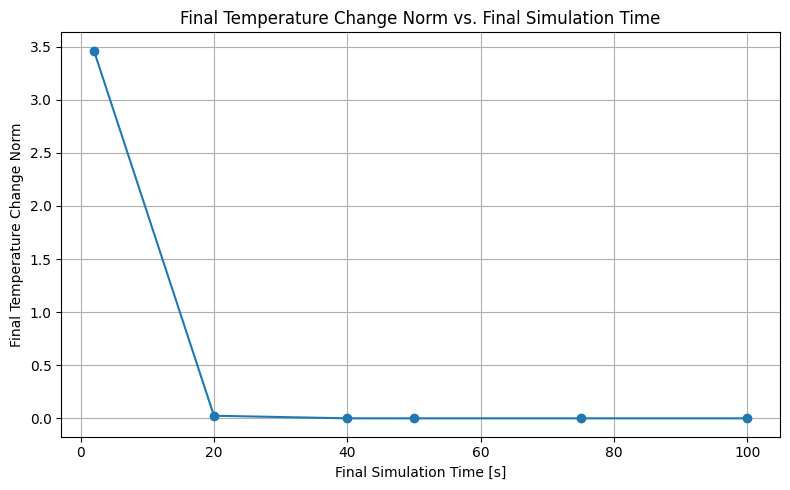



MESH REFINEMENT CONVERGENCE STUDY
Testing N =   10 ... CONVERGED
Testing N =   11 ... CONVERGED
Testing N =   12 ... CONVERGED
Testing N =   13 ... CONVERGED
Testing N =   14 ... CONVERGED
Testing N =   15 ... CONVERGED
Testing N =   16 ... CONVERGED
Testing N =   17 ... CONVERGED
Testing N =   18 ... CONVERGED
Testing N =   19 ... CONVERGED
Testing N =   20 ... CONVERGED
Testing N =   21 ... CONVERGED
Testing N =   22 ... CONVERGED
Testing N =   23 ... CONVERGED
Testing N =   24 ... CONVERGED
Testing N =   25 ... CONVERGED
Testing N =   26 ... CONVERGED
Testing N =   27 ... CONVERGED
Testing N =   28 ... CONVERGED
Testing N =   29 ... CONVERGED
Testing N =   30 ... CONVERGED
Testing N =   31 ... CONVERGED
Testing N =   32 ... CONVERGED
Testing N =   33 ... CONVERGED
Testing N =   34 ... CONVERGED
Testing N =   35 ... CONVERGED
Testing N =   36 ... CONVERGED
Testing N =   37 ... CONVERGED
Testing N =   38 ... CONVERGED
Testing N =   39 ... CONVERGED
Testing N =   40 ... CONVERGED
Tes

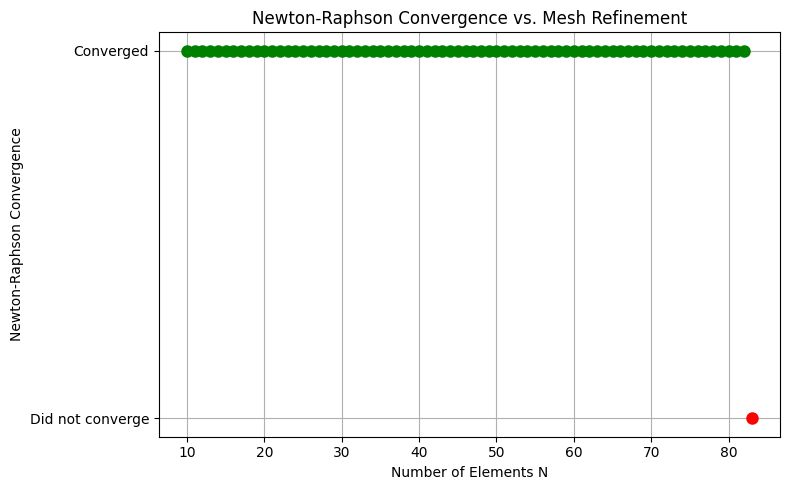



TABLE 1 - NEWTON / DIRECT SOLVER CONVERGENCE DATA


,Time Step,Newton Iterations,Direct Linear Solves,Nonlinear Residual Norm,Newton Correction Norm,Temperature Change Norm
0,1,9,9,5.255294e-10,7.104120e-13,106.490000
1,2,8,8,4.321104e-09,5.823309e-12,20.781394
2,3,8,8,9.700144e-09,9.073025e-12,13.775720
3,4,9,9,5.334231e-10,3.908984e-13,10.409710
4,5,9,9,7.579404e-10,5.308040e-13,8.477005
5,6,9,9,8.199911e-10,8.012071e-13,7.227085
6,7,9,9,9.691305e-10,1.036321e-12,6.361426
7,8,9,9,1.569686e-09,1.174161e-12,5.738572
8,9,9,9,1.579955e-09,1.280231e-12,5.279289
9,10,9,9,2.263513e-09,1.336359e-12,4.933072




TABLE 2 - TEMPERATURE DISTRIBUTION DATA


,Position [m],T at 25% final time [degC],T at 50% final time [degC],T at 75% final time [degC],T at 100% final time [degC]
0,0.000,100.000000,100.000000,100.000000,100.000000
1,0.001,64.724351,75.102367,79.814884,82.823699
2,0.002,40.515177,53.966034,61.674254,67.099465
3,0.003,29.509348,39.456884,47.732329,54.566447
4,0.004,26.046703,31.692012,39.167782,46.540164
5,0.005,25.377540,29.348468,36.308876,43.784245
6,0.006,26.046703,31.692012,39.167782,46.540164
7,0.007,29.509348,39.456884,47.732329,54.566447
8,0.008,40.515177,53.966034,61.674254,67.099465
9,0.009,64.724351,75.102367,79.814884,82.823699




TABLE 3 - FINAL TEMPERATURE CHANGE NORM


,Final Simulation Time [s],Final Temperature Change Norm
0,2,3.461295e+00
1,20,2.443267e-02
2,40,9.516249e-05
3,50,5.938178e-06
4,75,5.775931e-09
5,100,5.600159e-12




TABLE 4 - MESH REFINEMENT CONVERGENCE


,Number of Elements N,Element Size h [m],Newton-Raphson Convergence
0,10,0.001000,Converged
1,11,0.000909,Converged
2,12,0.000833,Converged
3,13,0.000769,Converged
4,14,0.000714,Converged
...,...,...,...
69,79,0.000127,Converged
70,80,0.000125,Converged
71,81,0.000123,Converged
72,82,0.000122,Converged




CSV FILES CREATED
1. newton_direct_solver_convergence_data.csv
2. temperature_distribution_data.csv
3. final_temperature_change_norm_data.csv
4. mesh_refinement_convergence_data.csv


In [ ]:
# -------------------------------

# Author: Luís Santos - 2026

# UAB - LISBON

# Nonlinear FEM for 1D heat conduction

# Implicit Euler method with Newton-Raphson iterations

# -------------------------------

import numpy as np

import matplotlib.pyplot as plt

import time

import psutil

import os

import tracemalloc

# =========================================================

# 1. USER INPUT

# =========================================================

L = float(input("Enter the length of the rod [m] L = "))

N = int(input("Enter the number of elements N = "))

q = float(input("Enter the linear heat generation [W/m] q = "))

t_final = float(input("Enter the final simulation time [s] t_final = "))

dt_input = float(input("Enter the time step [s] dt = "))

dt = min(dt_input, 0.1)

T_left = float(input("Temperature at left boundary [°C] T_left = "))

T_right = float(input("Temperature at right boundary [°C] T_right = "))

T_init = float(input("Initial temperature [°C] T_init = "))

# =========================================================

# 2. MATERIAL PARAMETERS

# =========================================================


alpha = 9.248

beta = 1.571e-2

gamma = 458.98

delta = 13.28e-2

eta = 8084.2

zeta = -0.42086

xi = -3.8942e-5

# =========================================================

# 3. MESH AND INITIALIZATION

# =========================================================

h = L / N

x = np.linspace(0, L, N + 1)

T = np.ones(N + 1) * T_init

nsteps = int(t_final / dt)

# =========================================================

# Global heat generation vector

# =========================================================

f_vec = np.ones(N + 1)

f_vec[1:N] = 2

f_vec = (q * h / 2.0) * f_vec


# =========================================================

# 4. FEM ASSEMBLY FUNCTIONS

# =========================================================

# ---------------------------------------------------------

# Mass matrix diagonal coefficient M_jj

# ---------------------------------------------------------

def M_jj(T, j):

    Tjm1 = T[j-1]

    Tj   = T[j]

    Tjp1 = T[j+1]

    term1 = (eta * gamma) / 3

    term2 = (

        0.25

        * (eta * delta + zeta * gamma)

        * (Tjm1 + Tj)

    )


    term3 = (

        0.2

        * (zeta * delta + xi * gamma)

        * (

            Tjm1**2

            + Tj**2

            + Tjm1 * Tj

        )

    )


    term4 = (

        (1/6)

        * xi * delta

        * (

            Tjm1**3

            + Tj**3

            + Tjm1**2 * Tj

            + Tjm1 * Tj**2

        )

    )

    term5 = (eta * gamma) / 3

    term6 = (

        0.25

        * (eta * delta + zeta * gamma)

        * (Tj + Tjp1)

    )

    term7 = (

        0.2

        * (zeta * delta + xi * gamma)

        * (

            Tj**2

            + Tjp1**2

            + Tj * Tjp1

        )

    )

    term8 = (

        (1/6)

        * xi * delta

        * (

            Tj**3

            + Tjp1**3

            + Tj**2 * Tjp1

            + Tj * Tjp1**2

        )

    )

    return h * (

        term1

        + term2

        + term3

        + term4

        + term5

        + term6

        + term7

        + term8

    )


# ---------------------------------------------------------

# Mass matrix upper off-diagonal coefficient M_j,j+1

# ---------------------------------------------------------

def M_jjp1(T, j):


    Tj = T[j]

    Tjp1 = T[j+1]


    dT = Tjp1 - Tj

    term1 = (eta * gamma) / 6

    term2 = (

        (1/6)

        * (eta * delta + zeta * gamma)

        * Tj

    )


    term3 = (

        (1/12)

        * (eta * delta + zeta * gamma)

        * dT

    )


    term4 = (

        (1/6)

        * (zeta * delta + xi * gamma)

        * Tj**2

    )


    term5 = (

        (1/6)

        * (zeta * delta + xi * gamma)

        * Tj * dT

    )


    term6 = (

        (1/20)

        * (zeta * delta + xi * gamma)

        * dT**2

    )


    term7 = (

        (1/6)

        * xi * delta

        * Tj**3

    )


    term8 = (

        (1/4)

        * xi * delta

        * Tj**2 * dT

    )


    term9 = (

        (3/20)

        * xi * delta

        * Tj * dT**2

    )


    term10 = (

        (1/30)

        * xi * delta

        * dT**3

    )


    return h * (

        term1

        + term2

        + term3

        + term4

        + term5

        + term6

        + term7

        + term8

        + term9

        + term10

    )


# ---------------------------------------------------------

# Mass matrix lower off-diagonal coefficient M_j,j-1

# ---------------------------------------------------------



def M_jmj(T, j):



    Tjm1 = T[j-1]

    Tj = T[j]

    dT = Tj - Tjm1

    term1 = (eta * gamma) / 6

    term2 = (

        (1/6)

        * (eta * delta + zeta * gamma)

        * Tjm1

    )


    term3 = (

        (1/12)

        * (eta * delta + zeta * gamma)

        * dT

    )


    term4 = (

        (1/6)

        * (zeta * delta + xi * gamma)

        * Tjm1**2

    )



    term5 = (

        (1/6)

        * (zeta * delta + xi * gamma)

        * Tjm1 * dT

    )



    term6 = (

        (1/20)

        * (zeta * delta + xi * gamma)

        * dT**2

    )



    term7 = (

        (1/6)

        * xi * delta

        * Tjm1**3

    )



    term8 = (

        (1/4)

        * xi * delta

        * Tjm1**2 * dT

    )



    term9 = (

        (3/20)

        * xi * delta

        * Tjm1 * dT**2

    )



    term10 = (

        (1/30)

        * xi * delta

        * dT**3

    )



    return h * (

        term1

        + term2

        + term3

        + term4

        + term5

        + term6

        + term7

        + term8

        + term9

        + term10

    )


# =========================================================

# Derivatives of mass matrix terms

# =========================================================


# ---------------------------------------------------------

# dM_j,j-1 / dT_j-1

# ---------------------------------------------------------



def dMjm1j_dTjm1(T, j):



    Tjm1 = T[j-1]

    Tj = T[j]


    return h * (

        (1/12) * (eta * delta + zeta * gamma)



        + (1/10)

        * (zeta * delta + xi * gamma)

        * Tjm1



        + (1/15)

        * (zeta * delta + xi * gamma)

        * Tj



        + (1/10)

        * xi * delta

        * Tjm1**2



        + (1/10)

        * xi * delta

        * Tjm1 * Tj



        + (1/20)

        * xi * delta

        * Tj**2

    )

# ---------------------------------------------------------

# dM_j,j-1 / dT_j

# ---------------------------------------------------------



def dMjm1j_dTj(T, j):



    Tjm1 = T[j-1]

    Tj = T[j]



    return h * (

        (1/12) * (eta * delta + zeta * gamma)



        + (1/15)

        * (zeta * delta + xi * gamma)

        * Tjm1



        + (1/10)

        * (zeta * delta + xi * gamma)

        * Tj



        + (1/20)

        * xi * delta

        * Tjm1**2



        + (1/10)

        * xi * delta

        * Tjm1 * Tj

        + (1/10)

        * xi * delta

        * Tj**2

    )



# ---------------------------------------------------------

# dM_jj / dT_j-1

# ---------------------------------------------------------



def dMjj_dTjm1(T, j):



    Tjm1 = T[j-1]

    Tj = T[j]

    Tjp1 = T[j+1]



    return h * (

        (1/4) * (eta * delta + zeta * gamma)



        + (1/5)

        * (zeta * delta + xi * gamma)

        * (2 * Tjm1 + Tj)



        + (1/6)

        * xi * delta

        * (

            3 * Tjm1**2

            + 2 * Tjm1 * Tj

            + Tj**2

        )

    )


# ---------------------------------------------------------

# dM_jj / dT_j

# ---------------------------------------------------------



def dMjj_dTj(T, j):



    Tjm1 = T[j-1]

    Tj = T[j]

    Tjp1 = T[j+1]



    return h * (

        (1/2) * (eta * delta + zeta * gamma)



        + (zeta * delta + xi * gamma)

        * (

            (4/5) * Tj

            + (1/5) * Tjm1

            + (1/5) * Tjp1

        )



        + xi * delta

        * (

            Tj**2

            + (1/3) * Tj * Tjm1

            + (1/3) * Tj * Tjp1

            + (1/6) * Tjm1**2

            + (1/6) * Tjp1**2

        )

    )


# ---------------------------------------------------------

# dM_jj / dT_j+1

# ---------------------------------------------------------



def dMjj_dTjp1(T, j):



    Tj = T[j]

    Tjp1 = T[j+1]



    return h * (

        (1/4) * (eta * delta + zeta * gamma)



        + (1/5)

        * (zeta * delta + xi * gamma)

        * Tj



        + (2/5)

        * (zeta * delta + xi * gamma)

        * Tjp1



        + (1/6)

        * xi * delta

        * Tj**2



        + (1/3)

        * xi * delta

        * Tj * Tjp1



        + (1/2)

        * xi * delta

        * Tjp1**2

    )


# ---------------------------------------------------------

# dM_j,j+1 / dT_j

# ---------------------------------------------------------



def dMjjp1_dTj(T, j):



    Tj = T[j]

    Tjp1 = T[j+1]



    return h * (

        (1/12) * (eta * delta + zeta * gamma)



        + (1/15)

        * (zeta * delta + xi * gamma)

        * Tj



        + (1/10)

        * (zeta * delta + xi * gamma)

        * Tjp1



        + (1/20)

        * xi * delta

        * Tj**2



        + (1/10)

        * xi * delta

        * Tj * Tjp1



        + (1/10)

        * xi * delta

        * Tjp1**2

    )

# ---------------------------------------------------------

# dM_j,j+1 / dT_j+1

# ---------------------------------------------------------



def dMjjp1_dTjp1(T, j):



    Tj = T[j]

    Tjp1 = T[j+1]



    return h * (

        (1/12) * (eta * delta + zeta * gamma)



        + (1/10)

        * (zeta * delta + xi * gamma)

        * Tj



        + (1/15)

        * (zeta * delta + xi * gamma)

        * Tjp1



        + (1/10)

        * xi * delta

        * Tj**2



        + (1/10)

        * xi * delta

        * Tj * Tjp1



        + (1/20)

        * xi * delta

        * Tjp1**2

    )

# =========================================================

# Stiffness matrix terms

# =========================================================



def K_jj(T, j):



    return (1 / h) * (

        2 * alpha

        + 0.5 * beta

        * (

            T[j-1]

            + 2 * T[j]

            + T[j+1]

        )

    )





def K_jjm1(T, j):



    return -(1 / h) * (

        alpha

        + 0.5 * beta

        * (

            T[j-1]

            + T[j]

        )

    )





def K_jjp1(T, j):



    return -(1 / h) * (

        alpha

        + 0.5 * beta

        * (

            T[j]

            + T[j+1]

        )

    )

# =========================================================

# Boundary/source contribution

# =========================================================



def compute_B(T, j):



    B = np.zeros(N + 1)



    B[j-1] = (

        T[j] / h

        * (

            alpha

            + beta * T[j-1]

        )

    )



    B[j+1] = -(

        T[j] / h

        * (

            alpha

            + beta * T[j+1]

        )

    )



    return B


# =========================================================

# 5. RESIDUAL FUNCTION

# =========================================================



def residual(T_new, T_old):



    F = np.zeros(N + 1)



    for j in range(1, N):



        # Mass matrix coefficients

        Mjj = M_jj(T_new, j)

        Mjmj = M_jmj(T_new, j)

        Mjjp1 = M_jjp1(T_new, j)



        # Stiffness coefficients

        Kj = K_jj(T_new, j)

        Kjm1 = K_jjm1(T_new, j)

        Kjp1 = K_jjp1(T_new, j)



        # Boundary contribution

        B_term = compute_B(T_new, j)



        # Transient contribution

        M_term = (

            Mjmj

            * (T_new[j-1] - T_old[j-1])



            + Mjj

            * (T_new[j] - T_old[j])



            + Mjjp1

            * (T_new[j+1] - T_old[j+1])

        ) / dt



        # Conductive contribution

        f_term = (

            Kj * T_new[j]

            + Kjm1 * T_new[j-1]

            + Kjp1 * T_new[j+1]

        )



        # Nonlinear residual

        F[j] = (

            M_term

            + f_term

            - B_term[j]

            - f_vec[j]

        )



    # Dirichlet boundary conditions

    F[0] = 0.0

    F[-1] = 0.0



    return F

# =========================================================

# 6. JACOBIAN FUNCTION

# =========================================================


def jacobian(T_new, T_old):



    J = np.zeros((N + 1, N + 1))



    for j in range(1, N):



        Tjm1 = T_new[j-1]

        Tj = T_new[j]

        Tjp1 = T_new[j+1]


        # -------------------------------------------------

        # Mass matrix values

        # -------------------------------------------------



        Mjmj = M_jmj(T_new, j)

        Mjj = M_jj(T_new, j)

        Mjjp1 = M_jjp1(T_new, j)

        # -------------------------------------------------

        # Mass matrix derivatives

        #

        # IMPORTANT:

        # Use different names for the evaluated derivatives

        # to avoid conflict with the derivative functions.

        # -------------------------------------------------


        der_Mjmj_Tjm1 = dMjm1j_dTjm1(T_new, j)

        der_Mjmj_Tj = dMjm1j_dTj(T_new, j)



        der_Mjj_Tjm1 = dMjj_dTjm1(T_new, j)

        der_Mjj_Tj = dMjj_dTj(T_new, j)

        der_Mjj_Tjp1 = dMjj_dTjp1(T_new, j)



        der_Mjjp1_Tj = dMjjp1_dTj(T_new, j)

        der_Mjjp1_Tjp1 = dMjjp1_dTjp1(T_new, j)


        # -------------------------------------------------

        # Stiffness derivatives

        # -------------------------------------------------


        dKjj_dTjm1 = (1 / h) * 0.5 * beta

        dKjj_dTj = (1 / h) * beta

        dKjj_dTjp1 = (1 / h) * 0.5 * beta



        dKjm1_dTjm1 = -(1 / h) * 0.5 * beta

        dKjm1_dTj = -(1 / h) * 0.5 * beta



        dKjp1_dTj = -(1 / h) * 0.5 * beta

        dKjp1_dTjp1 = -(1 / h) * 0.5 * beta


        # -------------------------------------------------

        # Boundary contribution derivatives

        # -------------------------------------------------

        dB_dTjm1 = (

            Tj / h

        ) * beta



        dB_dTj = (

            (1 / h)

            * (alpha + beta * Tjm1)

            -

            (1 / h)

            * (alpha + beta * Tjp1)

        )



        dB_dTjp1 = (

            -(Tj / h) * beta

        )

        # =================================================

        # Derivative with respect to T\_{j-1}

        # =================================================


        dF_dTjm1 = (



            # Mass contribution

            der_Mjmj_Tjm1

            * (Tjm1 - T_old[j-1])

            / dt



            + Mjmj / dt



            + der_Mjj_Tjm1

            * (Tj - T_old[j])

            / dt



            # Stiffness contribution

            + K_jjm1(T_new, j)



            + dKjj_dTjm1 * Tj



            + dKjm1_dTjm1 * Tjm1



            # Boundary contribution

            - dB_dTjm1

        )


        # =================================================

        # Derivative with respect to T_j

        # =================================================



        dF_dTj = (



            # Mass contribution

            der_Mjmj_Tj

            * (Tjm1 - T_old[j-1])

            / dt



            + der_Mjj_Tj

            * (Tj - T_old[j])

            / dt



            + Mjj / dt



            + der_Mjjp1_Tj

            * (Tjp1 - T_old[j+1])

            / dt



            # Stiffness contribution

            + K_jj(T_new, j)



            + dKjm1_dTj * Tjm1



            + dKjj_dTj * Tj



            + dKjp1_dTj * Tjp1



            # Boundary contribution

            - dB_dTj

        )


        # =================================================

        # Derivative with respect to T\_{j+1}

        # =================================================


        dF_dTjp1 = (



            # Mass contribution

            der_Mjj_Tjp1

            * (Tj - T_old[j])

            / dt



            + der_Mjjp1_Tjp1

            * (Tjp1 - T_old[j+1])

            / dt



            + Mjjp1 / dt



            # Stiffness contribution

            + K_jjp1(T_new, j)



            + dKjj_dTjp1 * Tj



            + dKjp1_dTjp1 * Tjp1



            # Boundary contribution

            - dB_dTjp1

        )



        # -------------------------------------------------

        # Assemble Jacobian row

        # -------------------------------------------------



        J[j, j-1] = dF_dTjm1

        J[j, j] = dF_dTj

        J[j, j+1] = dF_dTjp1



    return J

# =========================================================

# 7. PERFORMANCE TRACKING

# =========================================================



total_iterations = 0



residual_norms_nonlinear = []

correction_norms = []

error_norms = []



nonlinear_iterations_per_timestep = []

linear_solves_per_timestep = []



# Memory measurement

initial_memory = psutil.Process(

    os.getpid()

).memory_info().rss



tracemalloc.start()



t_start = time.time()


# =========================================================

# 7.1. PARAMETRIC STUDY: FINAL TEMPERATURE CHANGE NORM

# =========================================================



def run_temperature_change_simulation(t_final_test):



    # Number of time steps

    nsteps_test = int(t_final_test / dt)

    # Initial temperature field
    T_test = np.ones(N + 1) * T_init

    # Store temperature change norm for each time step

    error_norms_test = []
    # -----------------------------------------------------

    # Time integration

    # -----------------------------------------------------

    for step in range(1, nsteps_test + 1):

        # Temperature from previous time step

        T_old_test = T_test.copy()

        # -------------------------------------------------

        # Newton-Raphson iterations

        # -------------------------------------------------

        converged = False

        for k in range(1000):


            # Enforce Dirichlet boundary conditions

            T_test[0] = T_left

            T_test[-1] = T_right

            # Nonlinear residual

            F_test = residual(T_test, T_old_test)

            # Analytical Jacobian

            J_test = jacobian(T_test, T_old_test)

            # Direct solution of Newton linear system

            dT_test = np.linalg.solve(

                J_test[1:N, 1:N],

                -F_test[1:N]

            )

            # Newton update

            T_test[1:N] += dT_test

            # Re-enforce boundary conditions

            T_test[0] = T_left

            T_test[-1] = T_right

            # Residual after Newton update

            F_new_test = residual(T_test, T_old_test)

            res_norm_test = np.linalg.norm(

                F_new_test[1:N]

            )


            # Convergence criterion

            if res_norm_test < 1e-8:

                converged = True

                break


        if not converged:

            raise RuntimeError(

                f"Newton-Raphson did not converge at "

                f"t = {step * dt:.6e} s "

                f"for t_final = {t_final_test} s."

            )


        # Temperature change during this time step

        temperature_change_norm = np.linalg.norm(

            T_test - T_old_test

        )



        error_norms_test.append(

            temperature_change_norm

        )



    # Return final temperature change norm

    return error_norms_test[-1]

# =========================================================

# 8. TIME INTEGRATION LOOP

# =========================================================



T_saved = []



save_times = [

    0.25 * t_final,

    0.50 * t_final,

    0.75 * t_final,

    t_final

]



save_steps = [

    int(t / dt)

    for t in save_times

]

for step in range(1, nsteps + 1):


    # Temperature from previous time step

    T_old = T.copy()



    # -----------------------------------------------------

    # Newton-Raphson iterations

    # -----------------------------------------------------


    converged = False



    for k in range(1000):



        # Enforce Dirichlet boundary conditions

        T[0] = T_left

        T[-1] = T_right



        # Evaluate nonlinear residual

        F = residual(T, T_old)



        # Evaluate analytical Jacobian

        J = jacobian(T, T_old)



        # -------------------------------------------------

        # Direct solution of the Newton linear system

        #

        # J * dT = -F

        #

        # Only the interior unknowns are solved.

        # -------------------------------------------------



        dT = np.linalg.solve(

            J[1:N, 1:N],

            -F[1:N]

        )



        # Newton update

        T[1:N] += dT



        # Re-enforce Dirichlet boundary conditions

        T[0] = T_left

        T[-1] = T_right



        # -------------------------------------------------

        # Evaluate residual AFTER Newton update

        # -------------------------------------------------



        F_new = residual(T, T_old)



        res_norm = np.linalg.norm(

            F_new[1:N]

        )



        # -------------------------------------------------

        # Convergence criterion

        # -------------------------------------------------



        if res_norm < 1e-8:



            converged = True

            break

    # -----------------------------------------------------

    # Check Newton convergence

    # -----------------------------------------------------



    if not converged:



        raise RuntimeError(

            f"Newton-Raphson did not converge at "

            f"time step {step} "

            f"(t = {step * dt:.6e} s). "

            f"Final residual norm = {res_norm:.6e}"

        )



    # -----------------------------------------------------

    # Performance quantities

    # -----------------------------------------------------



    total_iterations += k + 1



    residual_norms_nonlinear.append(

        res_norm

    )



    correction_norms.append(

        np.linalg.norm(dT)

    )



    nonlinear_iterations_per_timestep.append(

        k + 1

    )



    # One direct linear solve per Newton iteration

    linear_solves_per_timestep.append(

        k + 1

    )



    # Change in temperature during this time step

    error_norms.append(

        np.linalg.norm(T - T_old)

    )



    # -----------------------------------------------------

    # Save temperature field

    # -----------------------------------------------------



    if step in save_steps:



        T_saved.append(

            T.copy()

        )


# Convert saved solutions to array

T_saved = np.array(T_saved).T


# =========================================================

# 9. MEMORY AND EXECUTION TIME

# =========================================================


total_time = time.time() - t_start



final_memory = psutil.Process(

    os.getpid()

).memory_info().rss



memory_used = (

    final_memory - initial_memory

) / (1024 ** 2)



tracemalloc.stop()

# =========================================================

# 10. TEMPERATURE DISTRIBUTION PLOT

# =========================================================


plt.figure(figsize=(10, 5))


colors = ['r', 'g', 'm', 'b']


for i in range(len(save_times)):


    plt.plot(

        x,

        T_saved[:, i],

        color=colors[i],

        label=f't = {save_times[i]:.2f} s'

    )


plt.xlabel('Position [m]')

plt.ylabel('Temperature [°C]')

plt.title('Temperature Distribution Over Time')

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()



# =========================================================

# 11. NEWTON AND CONVERGENCE INFORMATION

# =========================================================

plt.figure(figsize=(12, 10))

# ---------------------------------------------------------

# Nonlinear iterations

# ---------------------------------------------------------


plt.subplot(2, 2, 1)



plt.plot(

    range(1, nsteps + 1),

    nonlinear_iterations_per_timestep,

    'b-o'

)



plt.xlabel('Time Steps')

plt.ylabel('Newton Iterations')

plt.title('Newton Iterations vs. Time Steps')

plt.grid(True)


# ---------------------------------------------------------

# Direct linear solves

# ---------------------------------------------------------


plt.subplot(2, 2, 2)



plt.plot(

    range(1, nsteps + 1),

    linear_solves_per_timestep,

    'r-o'

)


plt.xlabel('Time Steps')

plt.ylabel('Direct Linear Solves')

plt.title('Direct Linear Solves vs. Time Steps')

plt.grid(True)


# ---------------------------------------------------------

# Nonlinear residual

# ---------------------------------------------------------

plt.subplot(2, 2, 3)

plt.semilogy(

    range(1, nsteps + 1),

    residual_norms_nonlinear,

    'g-o'

)


plt.xlabel('Time Steps')

plt.ylabel('Nonlinear Residual Norm')

plt.title('Nonlinear Residual Norm vs. Time Steps')

plt.grid(True)


# ---------------------------------------------------------

# Newton correction

# ---------------------------------------------------------


plt.subplot(2, 2, 4)


plt.semilogy(

    range(1, nsteps + 1),

    correction_norms,

    'm-o'

)


plt.xlabel('Time Steps')

plt.ylabel('Newton Correction Norm')

plt.title('Newton Correction Norm vs. Time Steps')

plt.grid(True)


plt.tight_layout()

plt.show()


# =========================================================

# 12. PERFORMANCE REPORT

# =========================================================


print("\n--- Performance Summary ---")

print(

    f"Total Newton Iterations: "

    f"{total_iterations}"

)


print(

    f"Total Execution Time: "

    f"{total_time:.3f} seconds"

)

print(

    f"Average Newton Iterations per Time Step: "

    f"{total_iterations / nsteps:.2f}"

)

print(

    f"Final Residual Norm (Nonlinear): "

    f"{residual_norms_nonlinear[-1]:.2e}"

)


print(

    f"Final Linear-System Solution Norm: "

    f"{correction_norms[-1]:.2e}"

)


print(

    f"Final Temperature Change Norm: "

    f"{error_norms[-1]:.2e}"

)


print(

    f"Memory Usage: "

    f"{memory_used:.2f} MB"

)


print(

    f"Approximate Linear-System Solves: "

    f"{total_iterations}"

)

print(

    f"Stability Check (max T): "

    f"{np.max(T):.2f} °C"

)

print(

    f"Robustness: "

    f"{'OK' if np.max(T) < 1e4 else 'Check'}"

)

# =========================================================

# 13. FINAL TEMPERATURE CHANGE NORM VS. FINAL TIME

# =========================================================



t_final_values = [2, 20, 40, 50, 75,100]



final_temperature_change_norms = []



print("\n--- Final Temperature Change Norm Study ---")



for t_test in t_final_values:



    final_norm = run_temperature_change_simulation(

        t_test

    )



    final_temperature_change_norms.append(

        final_norm

    )



    print(

        f"t_final = {t_test:6.1f} s  -->  "

        f"Final Temperature Change Norm = "

        f"{final_norm:.2e}"

    )

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------



plt.figure(figsize=(8, 5))



plt.plot(

    t_final_values,

    final_temperature_change_norms,

    'o-'

)



plt.xlabel('Final Simulation Time [s]')

plt.ylabel('Final Temperature Change Norm')



plt.title(

    'Final Temperature Change Norm vs. Final Simulation Time'

)



plt.grid(True)

plt.tight_layout()

plt.show()


# =========================================================
# 14. MESH REFINEMENT: FIND FIRST NON-CONVERGENT N
# =========================================================


def test_convergence_for_N(N_test):
    """
    Run the complete transient simulation for a prescribed mesh size N_test
    and return True if all Newton iterations converge.

    The current code uses global N, h and f_vec inside the FEM functions,
    therefore these variables are temporarily changed here and restored
    before leaving the function.
    """

    global N, h, f_vec

    # Save original values
    N_original = N
    h_original = h
    f_vec_original = f_vec.copy()

    try:

        # -------------------------------------------------
        # Mesh for the current test
        # -------------------------------------------------

        N = int(N_test)
        h = L / N

        # -------------------------------------------------
        # Global heat generation vector for this mesh
        # -------------------------------------------------

        f_vec = np.ones(N + 1)
        f_vec[1:N] = 2
        f_vec = (q * h / 2.0) * f_vec

        # -------------------------------------------------
        # Initial temperature field
        # -------------------------------------------------

        T_test = np.full(
            N + 1,
            T_init,
            dtype=float
        )

        T_test[0] = T_left
        T_test[-1] = T_right

        # -------------------------------------------------
        # Number of time steps
        # -------------------------------------------------

        nsteps_test = int(t_final / dt)

        # -------------------------------------------------
        # Time integration
        # -------------------------------------------------

        for step in range(1, nsteps_test + 1):

            T_old = T_test.copy()
            converged = False

            # ---------------------------------------------
            # Newton-Raphson iterations
            # ---------------------------------------------

            for k in range(1000):

                # Enforce Dirichlet boundary conditions
                T_test[0] = T_left
                T_test[-1] = T_right

                # Residual
                F = residual(
                    T_test,
                    T_old
                )

                # Check residual for invalid values
                if not np.all(np.isfinite(F)):
                    return False

                # Jacobian
                J = jacobian(
                    T_test,
                    T_old
                )

                # Check Jacobian for invalid values
                if not np.all(np.isfinite(J)):
                    return False

                try:

                    # Direct solution of the Newton linear system
                    dT = np.linalg.solve(
                        J[1:N, 1:N],
                        -F[1:N]
                    )

                except np.linalg.LinAlgError:

                    # Singular or numerically unusable matrix
                    return False

                # Check Newton correction
                if not np.all(np.isfinite(dT)):
                    return False

                # Newton update
                T_test[1:N] += dT

                # Re-apply boundary conditions
                T_test[0] = T_left
                T_test[-1] = T_right

                # Residual after Newton update
                F_new = residual(
                    T_test,
                    T_old
                )

                # Check for NaN/Inf
                if not np.all(np.isfinite(F_new)):
                    return False

                # Nonlinear residual norm
                res_norm = np.linalg.norm(
                    F_new[1:N]
                )

                # Convergence criterion
                if res_norm < 1e-8:
                    converged = True
                    break

            # ---------------------------------------------
            # Check convergence of the current time step
            # ---------------------------------------------

            if not converged:
                return False

        # -------------------------------------------------
        # Complete transient simulation converged
        # -------------------------------------------------

        return True

    finally:

        # Restore original global mesh variables
        N = N_original
        h = h_original
        f_vec = f_vec_original


# =========================================================
# 14.1. PARAMETERS OF THE MESH STUDY
# =========================================================

print("\n")
print("=" * 70)
print("MESH REFINEMENT CONVERGENCE STUDY")
print("=" * 70)

# First mesh to test
N_start = 10

# Increase N by this amount at every test
N_increment = 1

# Safety limit: the search stops here if every tested mesh converges
N_max = 1000

# Store results
N_tested = []
convergence_results = []

first_non_convergent_N = None
last_convergent_N = None


# =========================================================
# 14.2. TEST SUCCESSIVELY REFINED MESHES
# =========================================================

for N_test in range(
    N_start,
    N_max + 1,
    N_increment
):

    print(
        f"Testing N = {N_test:4d} ... ",
        end="",
        flush=True
    )

    converged = test_convergence_for_N(
        N_test
    )

    N_tested.append(N_test)
    convergence_results.append(converged)

    if converged:

        last_convergent_N = N_test

        print("CONVERGED")

    else:

        first_non_convergent_N = N_test

        print("DID NOT CONVERGE")

        # Stop at the first non-convergent mesh
        break


# =========================================================
# 14.3. REPORT
# =========================================================

print("\n" + "=" * 70)
print("MESH REFINEMENT RESULT")
print("=" * 70)

if first_non_convergent_N is not None:

    print(
        f"First non-convergent mesh: N = "
        f"{first_non_convergent_N}"
    )

    print(
        f"Corresponding element size: h = "
        f"{L / first_non_convergent_N:.6e} m"
    )

    if last_convergent_N is not None:

        print(
            f"Last convergent mesh: N = "
            f"{last_convergent_N}"
        )

        print(
            f"Corresponding element size: h = "
            f"{L / last_convergent_N:.6e} m"
        )

else:

    print(
        f"All tested meshes converged up to N = {N_max}."
    )

print("=" * 70)


# =========================================================
# 14.4. PLOT CONVERGENCE / NON-CONVERGENCE
# =========================================================

plt.figure(figsize=(8, 5))

for i in range(len(N_tested)):

    if convergence_results[i]:

        plt.plot(
            N_tested[i],
            1,
            'go',
            markersize=8
        )

    else:

        plt.plot(
            N_tested[i],
            0,
            'ro',
            markersize=8
        )


plt.xlabel('Number of Elements N')

plt.ylabel('Newton-Raphson Convergence')

plt.yticks(
    [0, 1],
    ['Did not converge', 'Converged']
)

plt.title(
    'Newton-Raphson Convergence vs. Mesh Refinement'
)

plt.grid(True)

plt.tight_layout()

plt.show()
# =========================================================
# 15. EXPORT AND DISPLAY GRAPH DATA AS TABLES
# =========================================================

import pandas as pd


# =========================================================
# TABLE 1 - NEWTON / DIRECT SOLVER CONVERGENCE DATA
# =========================================================

newton_convergence_data = pd.DataFrame({
    "Time Step": range(
        1,
        len(nonlinear_iterations_per_timestep) + 1
    ),

    "Newton Iterations": nonlinear_iterations_per_timestep,

    "Direct Linear Solves": linear_solves_per_timestep,

    "Nonlinear Residual Norm": residual_norms_nonlinear,

    "Newton Correction Norm": correction_norms,

    "Temperature Change Norm": error_norms
})

newton_convergence_data.to_csv(
    "newton_direct_solver_convergence_data.csv",
    index=False
)

print("\n")
print("=" * 80)
print("TABLE 1 - NEWTON / DIRECT SOLVER CONVERGENCE DATA")
print("=" * 80)

display(newton_convergence_data)


# =========================================================
# TABLE 2 - TEMPERATURE DISTRIBUTION DATA
# =========================================================

temperature_distribution_data = pd.DataFrame({
    "Position [m]": x,

    "T at 25% final time [degC]":
        T_saved[:, 0],

    "T at 50% final time [degC]":
        T_saved[:, 1],

    "T at 75% final time [degC]":
        T_saved[:, 2],

    "T at 100% final time [degC]":
        T_saved[:, 3]
})

temperature_distribution_data.to_csv(
    "temperature_distribution_data.csv",
    index=False
)

print("\n")
print("=" * 80)
print("TABLE 2 - TEMPERATURE DISTRIBUTION DATA")
print("=" * 80)

display(temperature_distribution_data)


# =========================================================
# TABLE 3 - FINAL TEMPERATURE CHANGE NORM
# =========================================================

final_temperature_change_data = pd.DataFrame({
    "Final Simulation Time [s]":
        t_final_values,

    "Final Temperature Change Norm":
        final_temperature_change_norms
})

final_temperature_change_data.to_csv(
    "final_temperature_change_norm_data.csv",
    index=False
)

print("\n")
print("=" * 80)
print("TABLE 3 - FINAL TEMPERATURE CHANGE NORM")
print("=" * 80)

display(final_temperature_change_data)


# =========================================================
# TABLE 4 - MESH REFINEMENT CONVERGENCE
# =========================================================

mesh_refinement_data = pd.DataFrame({
    "Number of Elements N":
        N_tested,

    "Element Size h [m]": [
        L / N_test
        for N_test in N_tested
    ],

    "Newton-Raphson Convergence": [
        "Converged"
        if result
        else "Did not converge"
        for result in convergence_results
    ]
})

mesh_refinement_data.to_csv(
    "mesh_refinement_convergence_data.csv",
    index=False
)

print("\n")
print("=" * 80)
print("TABLE 4 - MESH REFINEMENT CONVERGENCE")
print("=" * 80)

display(mesh_refinement_data)


# =========================================================
# CSV FILES CREATED
# =========================================================

print("\n")
print("=" * 80)
print("CSV FILES CREATED")
print("=" * 80)

print("1. newton_direct_solver_convergence_data.csv")
print("2. temperature_distribution_data.csv")
print("3. final_temperature_change_norm_data.csv")
print("4. mesh_refinement_convergence_data.csv")